# Hands-On Data Lab
Setup, data manipulation, visualization and basic analysis on a synthetic retail sales dataset (seeded, so results are reproducible).

## 1. Environment check

In [1]:
import sys, platform
import numpy as np, pandas as pd, matplotlib, scipy, seaborn as sns, sklearn
import matplotlib.pyplot as plt
print('Python    ', sys.version.split()[0])
for m in (np, pd, matplotlib, scipy, sns, sklearn):
    print(f'{m.__name__:<11}', m.__version__)

Python     3.13.16
numpy       2.5.3
pandas      3.0.5
matplotlib  3.11.2
scipy       1.18.1
seaborn     0.13.2
sklearn     1.9.1


## 2. Create and load the dataset

In [2]:
rng = np.random.default_rng(42)
n = 500
df = pd.DataFrame({
    'order_date': pd.to_datetime('2025-01-01') + pd.to_timedelta(rng.integers(0, 365, n), unit='D'),
    'region': rng.choice(['North','South','East','West'], n, p=[.3,.2,.3,.2]),
    'category': rng.choice(['Electronics','Clothing','Grocery','Furniture'], n, p=[.25,.3,.35,.1]),
    'units': rng.integers(1, 10, n),
    'unit_price': rng.normal(60, 20, n).round(2).clip(5),
    'discount_pct': rng.choice([0,5,10,15,20], n),
})
# introduce realistic messiness
df.loc[rng.choice(n, 20, replace=False), 'unit_price'] = np.nan
df.loc[rng.choice(n, 15, replace=False), 'region'] = None
df = pd.concat([df, df.sample(8, random_state=1)], ignore_index=True)   # duplicates
df.to_csv('sales_raw.csv', index=False)
raw = pd.read_csv('sales_raw.csv', parse_dates=['order_date'])
print(raw.shape); raw.head()

(508, 6)


,order_date,region,category,units,unit_price,discount_pct
0,2025-02-02,East,Clothing,7,79.26,5
1,2025-10-10,West,Clothing,1,45.51,20
2,2025-08-27,South,Electronics,7,42.92,15
3,2025-06-10,North,Clothing,1,69.19,10
4,2025-06-08,North,Grocery,1,79.77,5


## 3. Data manipulation
### 3.1 Inspect

In [3]:
raw.info()
print()
print(raw.isna().sum())
print('Duplicate rows:', raw.duplicated().sum())

<class 'pandas.DataFrame'>
RangeIndex: 508 entries, 0 to 507
Data columns (total 6 columns):
 #   Column        Non-Null Count  Dtype         
---  ------        --------------  -----         
 0   order_date    508 non-null    datetime64[us]
 1   region        493 non-null    str           
 2   category      508 non-null    str           
 3   units         508 non-null    int64         
 4   unit_price    488 non-null    float64       
 5   discount_pct  508 non-null    int64         
dtypes: datetime64[us](1), float64(1), int64(2), str(2)
memory usage: 23.9 KB

order_date       0
region          15
category         0
units            0
unit_price      20
discount_pct     0
dtype: int64
Duplicate rows: 8


### 3.2 Clean

In [4]:
d = raw.drop_duplicates().copy()
d['region'] = d['region'].fillna('Unknown')
d['unit_price'] = d['unit_price'].fillna(d.groupby('category')['unit_price'].transform('median'))
print('Shape after cleaning:', d.shape)
print('Missing values left :', int(d.isna().sum().sum()))

Shape after cleaning: (500, 6)
Missing values left : 0


### 3.3 Feature engineering

In [5]:
d['revenue'] = d['units'] * d['unit_price'] * (1 - d['discount_pct']/100)
d['month'] = d['order_date'].dt.to_period('M').dt.to_timestamp()
d[['order_date','region','category','revenue']].head()

,order_date,region,category,revenue
0,2025-02-02,East,Clothing,527.0790
1,2025-10-10,West,Clothing,36.4080
2,2025-08-27,South,Electronics,255.3740
3,2025-06-10,North,Clothing,62.2710
4,2025-06-08,North,Grocery,75.7815


### 3.4 Group, aggregate, filter

In [6]:
by_cat = d.groupby('category')['revenue'].agg(['count','sum','mean']).round(2).sort_values('sum', ascending=False)
print(by_cat); print()
by_reg = d.groupby('region')['revenue'].sum().round(2).sort_values(ascending=False)
print(by_reg); print()
top = d[(d['revenue'] > 500) & (d['category']=='Electronics')]
print('Electronics orders over 500:', len(top))

             count       sum    mean
category                            
Grocery        173  47692.68  275.68
Clothing       144  37108.87  257.70
Electronics    134  36261.24  270.61
Furniture       49  11294.66  230.50

region
East       38163.84
North      37458.95
West       29848.45
South      23496.50
Unknown     3389.70
Name: revenue, dtype: float64

Electronics orders over 500: 17


## 4. Visualization

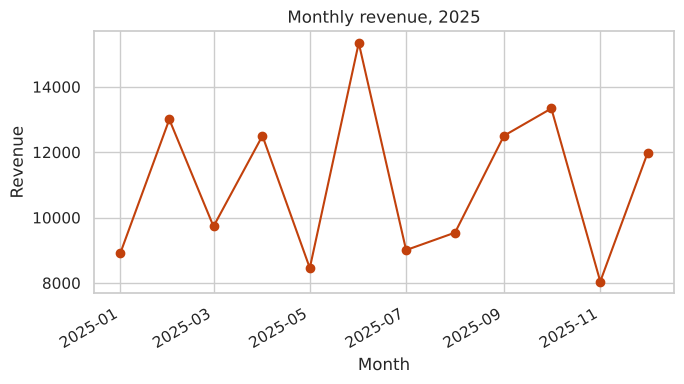

In [7]:
sns.set_theme(style='whitegrid')
fig, ax = plt.subplots(figsize=(7,4))
monthly = d.groupby('month')['revenue'].sum()
ax.plot(monthly.index, monthly.values, marker='o', color='#C2410C')
ax.set(title='Monthly revenue, 2025', xlabel='Month', ylabel='Revenue')
fig.autofmt_xdate(); fig.tight_layout(); fig.savefig('fig_monthly.png', dpi=150)

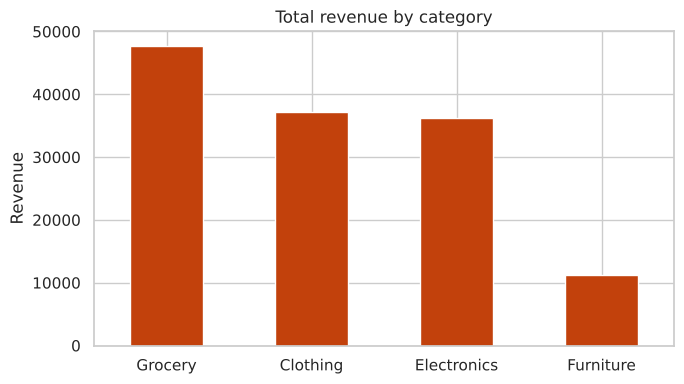

In [8]:
fig, ax = plt.subplots(figsize=(7,4))
by_cat['sum'].plot.bar(ax=ax, color='#C2410C')
ax.set(title='Total revenue by category', xlabel='', ylabel='Revenue'); plt.xticks(rotation=0)
fig.tight_layout(); fig.savefig('fig_category.png', dpi=150)

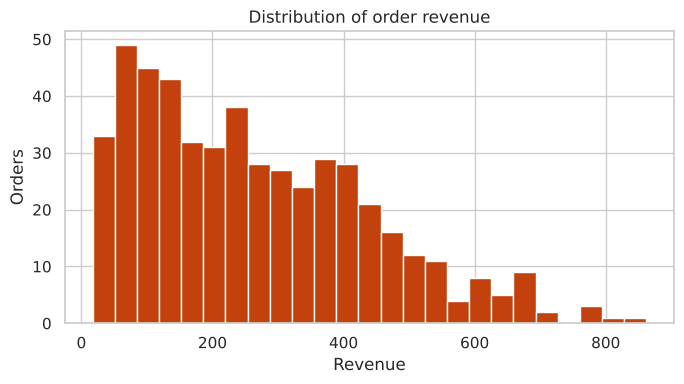

In [9]:
fig, ax = plt.subplots(figsize=(7,4))
ax.hist(d['revenue'], bins=25, color='#C2410C', edgecolor='white')
ax.set(title='Distribution of order revenue', xlabel='Revenue', ylabel='Orders')
fig.tight_layout(); fig.savefig('fig_hist.png', dpi=150)

## 5. Basic analysis

In [10]:
print(d['revenue'].describe().round(2))
print()
print(d[['units','unit_price','discount_pct','revenue']].corr().round(2))

count    500.00
mean     264.71
std      175.14
min       17.00
25%      117.40
50%      239.91
75%      380.95
max      861.92
Name: revenue, dtype: float64

              units  unit_price  discount_pct  revenue
units          1.00        0.00         -0.01     0.79
unit_price     0.00        1.00         -0.05     0.53
discount_pct  -0.01       -0.05          1.00    -0.14
revenue        0.79        0.53         -0.14     1.00


In [11]:
from scipy import stats
a = d.loc[d.category=='Electronics','revenue']; b = d.loc[d.category=='Grocery','revenue']
t, p = stats.ttest_ind(a, b, equal_var=False)
print(f'Electronics mean {a.mean():.2f} vs Grocery mean {b.mean():.2f}')
print(f'Welch t-test: t = {t:.2f}, p = {p:.4f}')

Electronics mean 270.61 vs Grocery mean 275.68
Welch t-test: t = -0.24, p = 0.8074


In [12]:
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import r2_score
X = d[['units','unit_price','discount_pct']]; y = d['revenue']
Xtr, Xte, ytr, yte = train_test_split(X, y, test_size=0.2, random_state=0)
m = LinearRegression().fit(Xtr, ytr)
print('R2 on held-out data:', round(r2_score(yte, m.predict(Xte)), 3))
print(dict(zip(X.columns, m.coef_.round(2))))

R2 on held-out data: 0.908
{'units': np.float64(53.48), 'unit_price': np.float64(4.58), 'discount_pct': np.float64(-2.77)}
